---
---

<h1><center><ins>Numerical Methods: Exam 1</ins></center></h1>
<h2><center>November 11, 09:45-11:15 </center></h2>

Please answer the short questions related to the numerical methods we discussed during the lectures. Provide short and concise (one-two sentences) answers.

Solve the two exercises in the python notebook, *documenting your code* where needed, or create .py files that are documented.

Remember to answer any discussion points asked in the question to obtain maximum points.  

***Before 11:20*** your files need to be uploaded to GitHub.<br>
<br>
This means you have roughly 90 minutes to complete the exercises and answer the questions.

You may use the lecture notes and any of your exercises freely, but you can **not** use ChatGPT code assistant or other AI coding tools such as Claude.<br> 
**_Collaboration or plagarized code except your own is prohibited and no phones or communication will be allowed_**.

---
---

In [1]:
from scipy.integrate import quad
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import inv, lu_solve, lu_factor
from scipy.interpolate import CubicSpline
from scipy import interpolate
from scipy import integrate

""" 
Set some defaults, most of all: LARGE fonts
"""
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'xx-large',
          'figure.figsize': (12, 7),
         'axes.labelsize': 'xx-large',
         'axes.titlesize':'xx-large',
         'xtick.labelsize':'xx-large',
         'ytick.labelsize':'xx-large'}
pylab.rcParams.update(params)

## Short questions
1. Name the root-finding methods we have discussed during the lectures, and rank them by their precision. Do all methods always converge? (**2 points**)
2. What is the difference between the trapezoid rule and the Simpson's rule in the Newton-Cotes numerical integration? (**2 points**)
3. What is the simplest way of expanding 1D interpolation methods to 2D? (**2 points**) 
4. What is LU decomposition and why is it used when solving sets of linear algebraic equations? (**2 points**)
5. What is the Jacobian matrix in the Newton-Raphson Method for nonlinear systems of equations? Can the Newton-Raphson method always find a solution for a nonlinear system of equations? (**2 points**)

1.)
1) Newton-Raphson, may not converge
2) Secant, may not converge
3) False position / Bisection (almost equal, slight advantage of false position): will always converge on a root or a divergence
2.)
Trapezoid uses a trapez, as name implies, consisting of (x_i, 0),(x_i, y_i); (x_i+1, 0), (x_i+1, y_i+1), so it is a linear approximation, Simpson uses a degree 2 polynomial as approximation
3)
Bilinear
4)
It decomposes the coefficient matrix into one, which has only diagonal and upper values, and another, which has only diagonal and lower values. By multiplying with the right hand side vector, I get the searched vector. I can use the same decomposition for several different RHS vectors
5)
The Jcobian matrix contains the partial derivatives of the function. In the position i,j it contains the derivative of f(x_i) with respect to x_j.
No, there is no guaratee that a nonlinear system of equations converges.

## Exercise 1. Interpolating the luminosity profile of a galaxy (10 Points)

Imagine an elliptical galaxy with the light intensity profile described by the de Vaucouleurs's law. We have observed four datapoints for the intensity in units of $L_\odot/pc^2$ at the corresponding radii in pc:

\begin{aligned}
(R_0,I_0) &= (0,\;2.14\times10^5),\\
(R_1,I_1) &= (1000,\;1.14\times10^3),\\
(R_2,I_2) &= (1500,\;5.51\times10^2),\\
(R_3,I_3) &= (2000,\;3.36\times10^2).
\end{aligned}


Use the Lagrange polynomial interpolation to fit a polynomial to these datapoints.

**(a)** What is the highest polynomial degree that you can fit to the four datapoints? (**1 point**)

**(b)** Interpolate the datapoints using your polynomial (**5 points** if you use your own Lagrange polynomial, **1 point** if you use embedded python fucntions).

**(c)** Use embedded functions for numerical integration such as **quad** or **simpson** to integrate your Lagrange polynomial that represents your luminosity profile from zero to 2000 pc to obtain the approximate luminosity of the galaxy in $L_\odot$. Use the print command to show the result (**2 points**)

**(d)** Plot your results: the four datapoints and the polynomial that you used to interpolate the function (**2 points**)


(a) The maximum degree is n-1 = 3

In [2]:
# (b)
R = np.array([0, 1000, 1500, 2000])
I = np.array([2.14e5, 1.14e3, 5.51e2, 3.36e2])

pol = interpolate.lagrange(R, I)
print(pol)

# according to SciPy manual, this is the replacement for the deprecated lagrange function
pol = interpolate.BarycentricInterpolator(R, I)

            3          2
-7.019e-05 x + 0.3166 x - 459.3 x + 2.14e+05


/var/folders/0v/hgyj042138z2mzg00d67ywzr0000gn/T/ipykernel_80492/846713372.py:5: DeprecationWarning: `lagrange` is deprecated and will be removed in SciPy 1.20.0. Use `scipy.interpolate.BarycentricInterpolator` instead.
  pol = interpolate.lagrange(R, I)


In [3]:
# (c)
Int = integrate.simpson(I, x=R)
print(f'Integral = {Int:.0f}')

Integral = 81738667


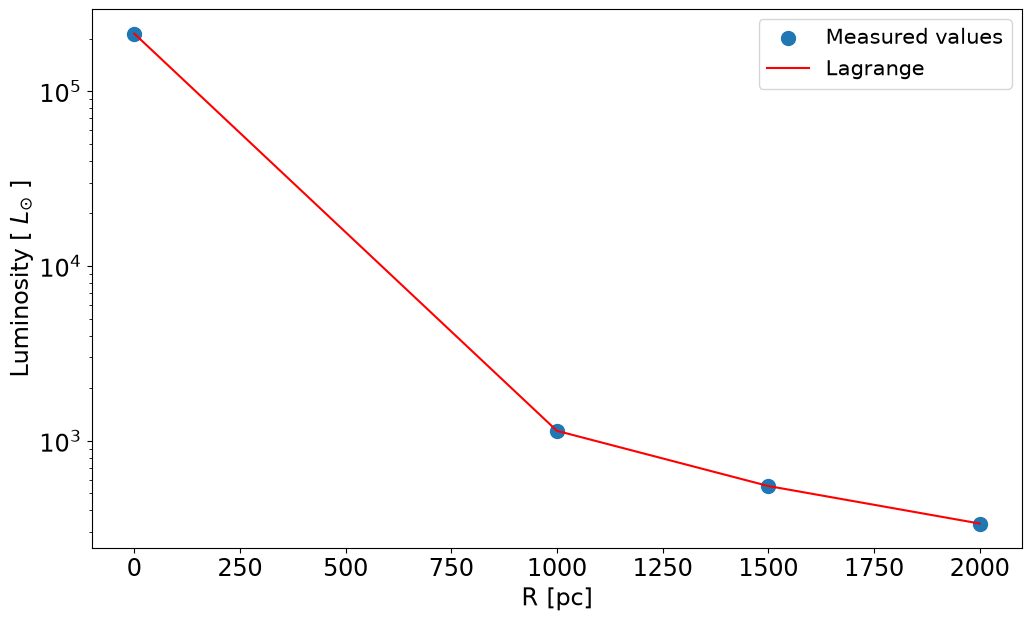

In [4]:
# (d)
plt.figure() 
plt.scatter(R, I, s=100, label='Measured values')
plt.plot(R, pol(R), color='red', label='Lagrange')
plt.xlabel('R [pc]',fontsize=17)
plt.ylabel(r'Luminosity [ $L_{\odot}$ ]',fontsize=17)
plt.legend(loc='best',fontsize=15)
plt.yscale('log')
plt.show()

## Exercise 2. Decelerating satellite and numerical derivation (10 Points)

A small spacecraft is decelerating. It's time-dependent coordinate is given by the following equation (the time is in seconds and the distance is in meters):

$$x(t) = 100 - 50 \exp (-0.2t)$$

**(a)** Determine the spacecraft's speed at $t=5$ s using the forward and central finite-difference methods (the non-symmetrical and symmetrical methods of calculating the numerical derivative) for the $dt = 1$ s (**2 points**)

**(b)** Investigate the accuracy of both methods for different step sizes. Create an array of step sizes ranging from 0.1 s to 2 s and calculate the derivatives for each $dt$ (**2 points**). Compare to the precise analytical formula for speed at $t=5$ s (**2 points**)

**(c)** Plot your results from **(b)** (**2 points**)

**(d)** Which method is more accurate, the central method or the forward method? (**1 point**). Why is one method more accurate than the other from the mathematical point of view (one sentence explanation is enough; **1 point**)



In [5]:
# (a)
# midpoint derivative
def deriv_sym(f, a, b, N):
    dy = []
    dx = (b - a) / N
    x1 = a - dx/2
    y1 = f(x1)
    for i in range(N):
        x2 = a + (i + 0.5) * dx         # in this way we avoid a drift by incrementing small values
        y2 = f(x2)
        dy.append((y2 - y1) / dx)
        x1, y1 = x2, y2
    return np.array(dy)

# forward derivative
def deriv_forw(f, a, b, N):
    dy = []
    dx = (b - a) / N
    x1 = a
    y1 = f(x1)
    for i in range(N):
        x2 = a + (i) * dx         # in this way we avoid a drift by incrementing small values
        y2 = f(x2)
        dy.append((y2 - y1) / dx)
        x1, y1 = x2, y2
    return np.array(dy)

#given function
def f(t):
    return 100 - 50 * np.exp(-0.2 * t)

# time derivative
def df(t):
    return 0.2 * 50 * np.exp(-0.2 * t)

# speed equals time derivative
speed_ana = df(5)

speed_sym = deriv_sym(f, 0, 5, 5)
speed_sym_5 = speed_sym[-1:][0]

speed_forw = deriv_forw(f, 0, 5, 5)
speed_for_5 = speed_forw[-1:][0]

#print(speed_sym, speed_sym_5)
#print(speed_forw, speed_for_5)

print(f'Analytical speed: {speed_ana:.2f}, speed numeric (central point): {speed_sym_5}, spped numeric (forward): {speed_for_5}')

Analytical speed: 3.68, speed numeric (central point): 4.50078220254052, spped numeric (forward): 4.974133598840254


Analytical speed: 3.68, dt = 0.1, speed numeric (central point): 3.753173540676471, spped numeric (forward): 3.7908935618561657
Analytical speed: 3.68, dt = 0.2, speed numeric (central point): 3.829184126780376, spped numeric (forward): 3.9065387773505478
Analytical speed: 3.68, dt = 0.4, speed numeric (central point): 3.9996536162637426, spped numeric (forward): 4.169826499467694
Analytical speed: 3.68, dt = 0.8, speed numeric (central point): 4.3510139037700295, spped numeric (forward): 4.729134631530838
Analytical speed: 3.68, dt = 1.0, speed numeric (central point): 4.50078220254052, spped numeric (forward): 4.974133598840254
Analytical speed: 3.68, dt = 1.5, speed numeric (central point): 5.157973536166659, spped numeric (forward): 6.093425746235911
Analytical speed: 3.68, dt = 2.0, speed numeric (central point): 6.128684606607808, spped numeric (forward): 7.869386805747331


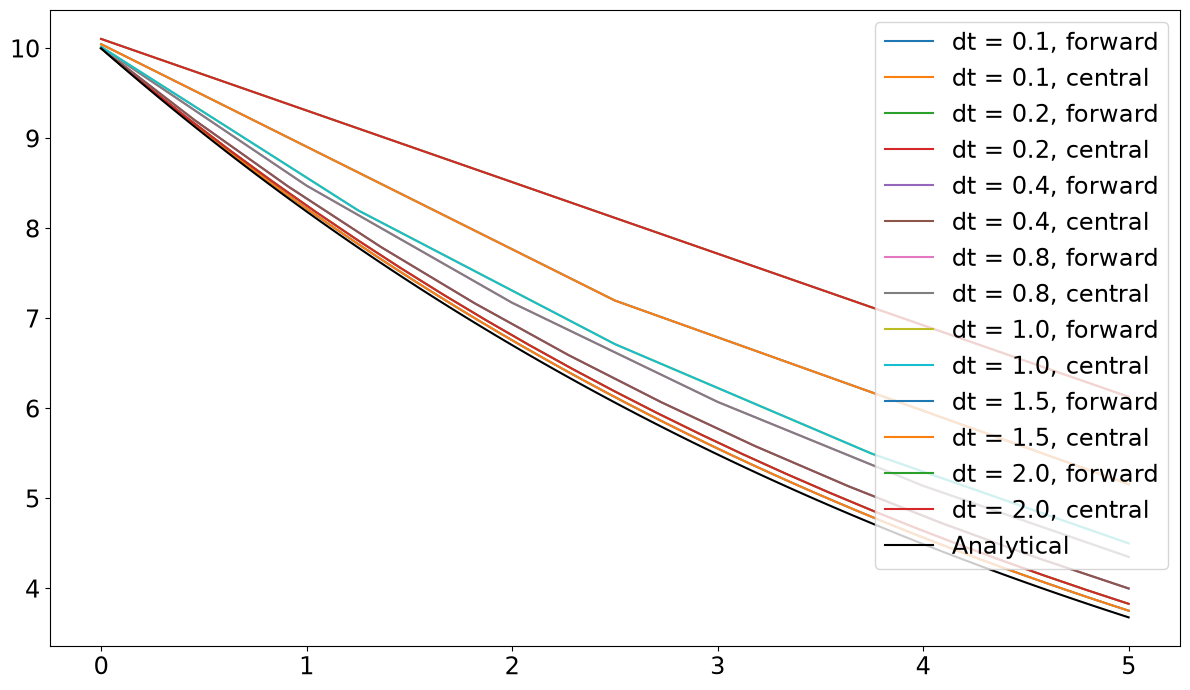

In [ ]:
# (b), (c)
dts = np.array([0.1, 0.2, 0.4, 0.8, 1.0, 1.5, 2])
start_t = 0
end_t = 5
#number of points
Ns = ((end_t - start_t) / dts).round()
#print(N)

plt.figure() 
for N, dt in zip(Ns, dts):
    speed_sym = deriv_sym(f, start_t, end_t, int(N))
    speed_sym_5 = speed_sym[-1:][0]
    xs = np.linspace(start_t, end_t, int(N))
    plt.plot(xs, speed_sym, label={f'dt = {dt}, forward'})
    plt.plot(xs, speed_sym, label={f'dt = {dt}, central'})

    speed_forw = deriv_forw(f, start_t, end_t, int(N))
    speed_for_5 = speed_forw[-1:][0]

    print(f'Analytical speed: {speed_ana:.2f}, dt = {dt}, speed numeric (central point): {speed_sym_5}, spped numeric (forward): {speed_for_5}')   

xs = np.linspace(start_t, end_t, 100)
plt.plot(xs, df(xs), color='black', label='Analytical')
plt.legend()
plt.tight_layout()
plt.show()


(d)
Central point is more accurate, because it gives us the slope at the midpoint, which represents the function better, than using the slope at the start point of an interval. The point in the center is more representative for the whole interval than the start of the interval.